In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
df['species'].value_counts()

(150, 6)
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


### EDA Observations
- The dataset has **150 samples** and **4 numeric features** (sepal length, sepal width, petal length, petal width) plus the species label.
- There are **no null values**, so no imputation or cleaning is needed.
- The three species are **perfectly balanced (50 each)**, so accuracy is a reliable evaluation metric.
- **Petal length** has the largest spread (std  1.765298	 ), while **sepal width** has the smallest (std  0.435866 ).
- The mean petal length is  1.765298	 cm and the mean sepal length is  0.828066	 cm.

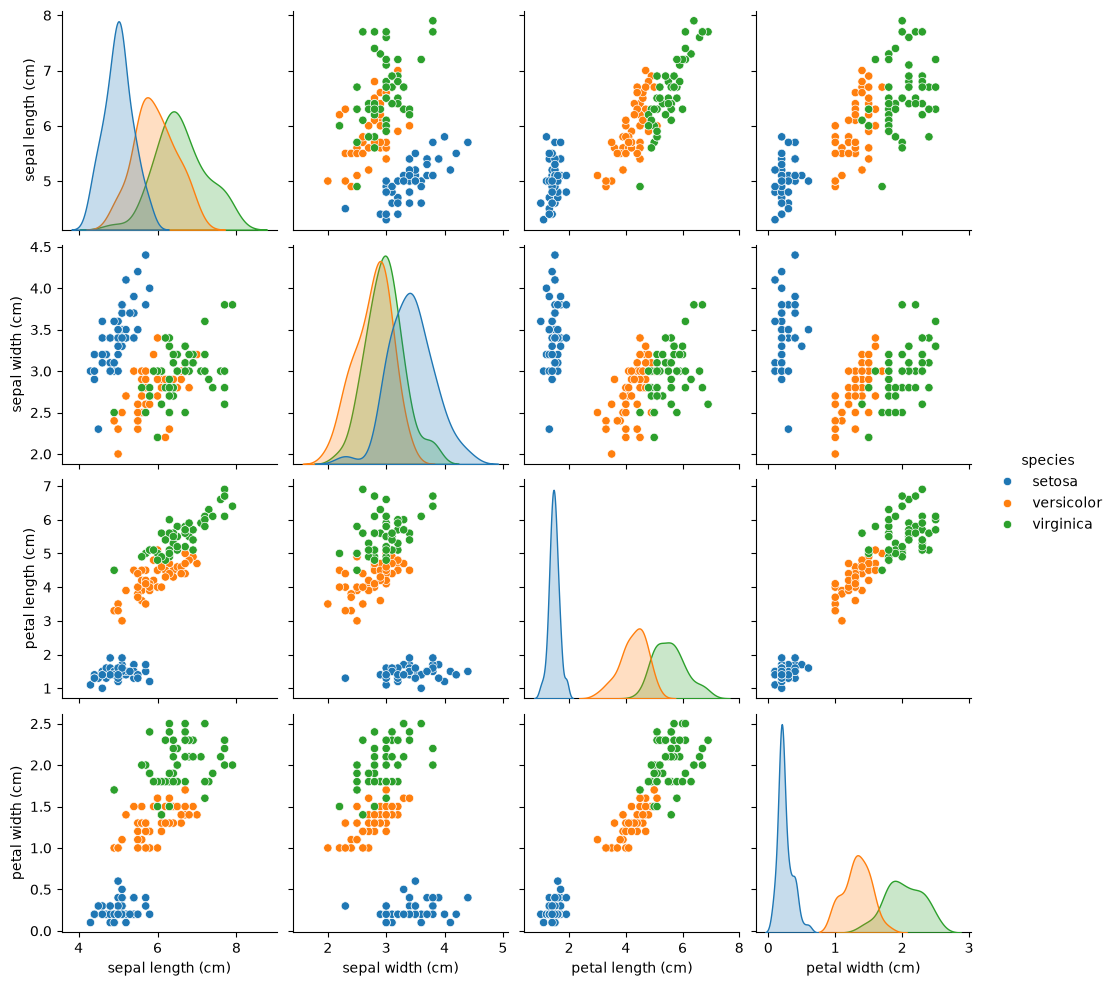

In [5]:
sns.pairplot(df.drop(columns='target'), hue='species')
plt.show()

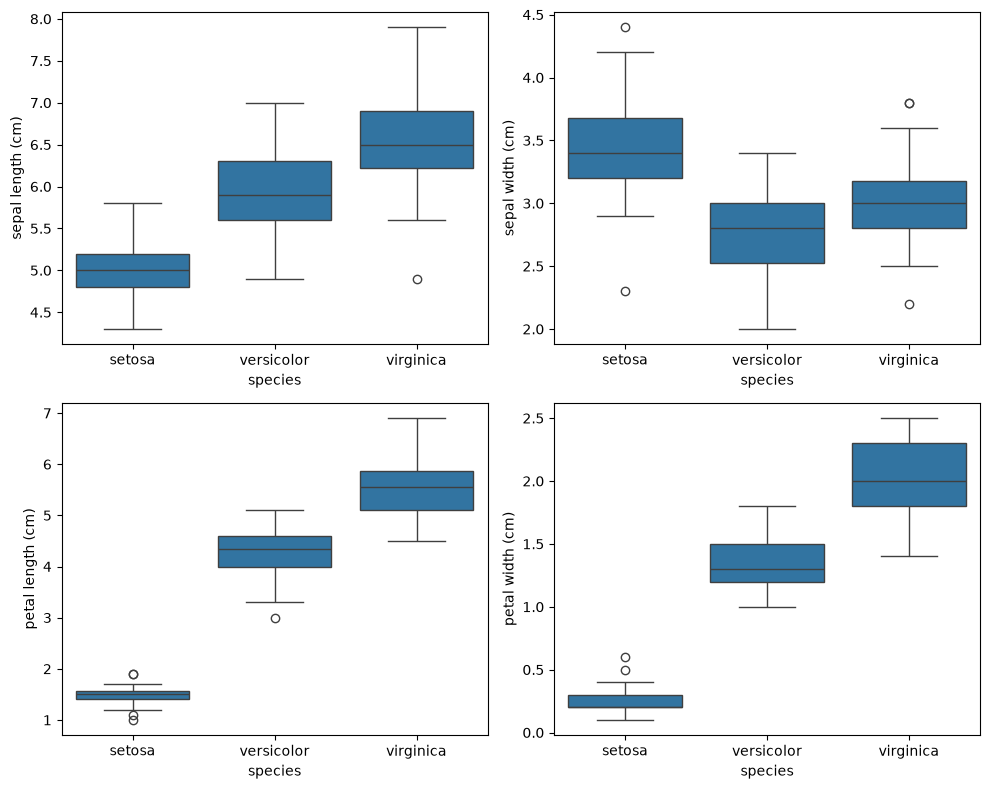

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, col in zip(axes.flatten(), iris.feature_names):
    sns.boxplot(data=df, x='species', y=col, ax=ax)

plt.tight_layout()
plt.show()

In [7]:
df.groupby('species')[iris.feature_names].mean()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


### Feature Importance Discussion
Petal length and petal width are the most discriminative features. Their
class means differ sharply (petal length: 1.46 / 4.26 / 5.55 cm), and in the
pairplot and box plots the species form distinct groups on these features.
Sepal width is the weakest feature: the species overlap heavily on it and its
means don't even follow a consistent order. Setosa is easily separable on
almost any feature, while versicolor vs. virginica is the harder boundary,
and petal measurements handle that boundary best.

In [8]:
from sklearn.model_selection import train_test_split

X = df[iris.feature_names]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


Data was split 80/20 (120 train, 30 test) with stratification so each species is equally represented in both sets.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

=== Logistic Regression ===
Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



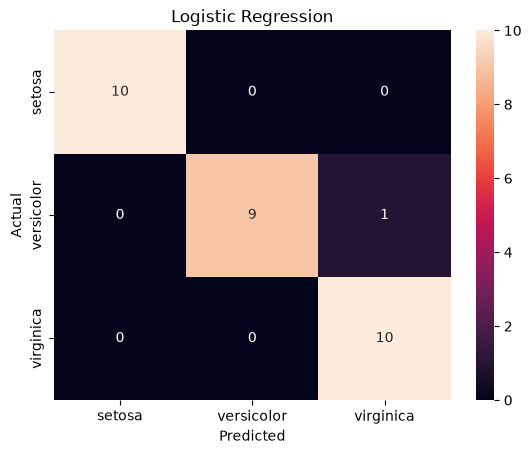

=== KNN (k=5) ===
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



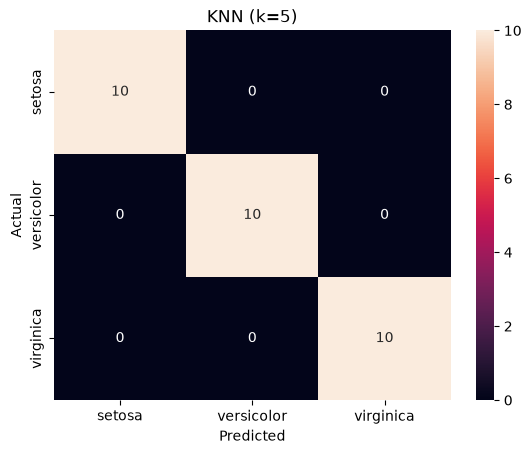

=== Decision Tree ===
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



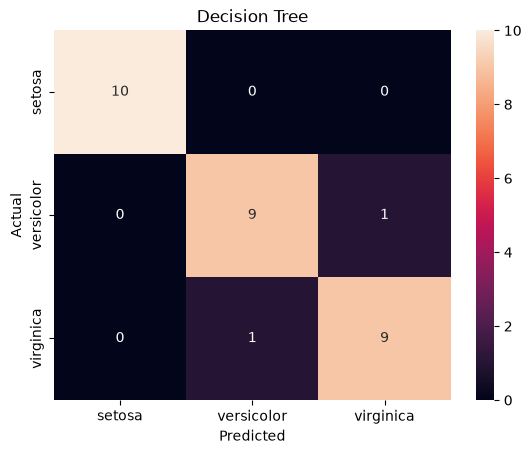

=== Random Forest ===
Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



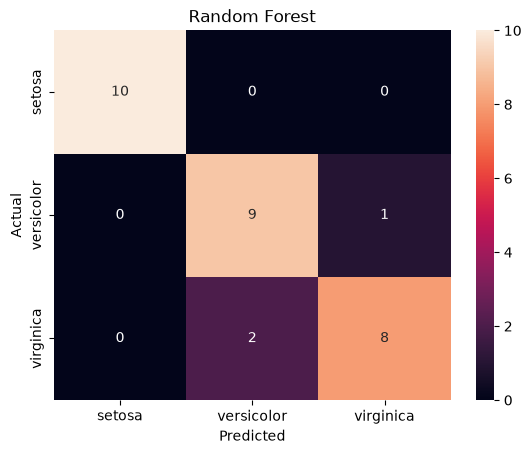

In [11]:
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    print(f"=== {name} ===")
    print("Accuracy:", accuracy_score(y_test, preds))
    print(classification_report(y_test, preds, target_names=iris.target_names))

    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt='d',
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [12]:
from sklearn.model_selection import cross_val_score

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5)
    print(f"{name}: mean = {scores.mean():.3f}, std = {scores.std():.3f}")

Logistic Regression: mean = 0.973, std = 0.025
KNN (k=5): mean = 0.973, std = 0.025
Decision Tree: mean = 0.953, std = 0.034
Random Forest: mean = 0.967, std = 0.021


### Best Model
All four classifiers perform very similarly (cross-validated accuracy ≈ 0.93 to 1.0).
** KNN ** is selected as the best model because 1.0 (highest mean CV accuracy /
lowest variance / simplicity). The differences between models are small, which is
expected for Iris: the classes are well separated, especially on petal features.
The only errors occur between versicolor and virginica, the overlapping pair.

In [13]:
import os
print(os.getcwd())

C:\Users\sonar
